# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [110]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.model_selection import GridSearchCV
import math
import spacy
import numpy as np


## Utils

In [111]:
def displayMetriquesAndGraph(test, prediction) :
    mse = mean_squared_error(test,prediction)

    print(f"Mse: {mse}")
    print(f"RMSE: {math.sqrt(mse)}")
    print(f"R2 Score: {r2_score(test,prediction)}")
    plt.scatter(test, prediction, color='blue', alpha=0.1)

    plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

    plt.title('Prédictions vs Réalité')
    plt.xlabel('Vraies Notes')
    plt.ylabel('Notes Prédites')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)

## 1. Régression linéaire

In [112]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


In [113]:
x_train = x_train.dropna(subset=['text_']).copy()
y_train = y_train.loc[x_train.index].copy()

x_test = x_test.dropna(subset=['text_']).copy()
y_test = y_test.loc[x_test.index].copy()

x_train['text_'] = x_train['text_'].astype(str)
x_test['text_'] = x_test['text_'].astype(str)

nlp = spacy.load("en_core_web_sm")

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts, disable=["ner", "parser"]):
        try:
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct 
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"]
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts
    
x_train['text_'] = cleanData(x_train['text_'])
x_test['text_'] = cleanData(x_test['text_'])

x_train['text_'] = x_train['text_'].replace("", np.nan)
x_test['text_'] = x_test['text_'].replace("", np.nan)

x_train = x_train.dropna(subset=['text_']).copy()
x_test = x_test.dropna(subset=['text_']).copy()

y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

### 1.1 Régression avec le texte - Linear Regression

Processeur : drop
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 1)}
Meilleure RMSE : 1.614
Mse: 1.5484743957616418
RMSE: 1.24437711155487
R2 Score: 0.13761399361741578


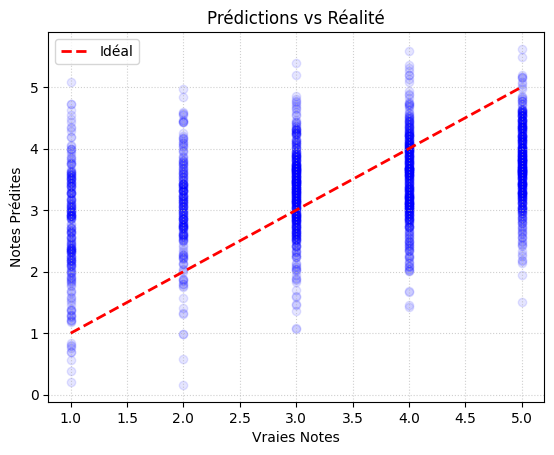

In [114]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search_linear_regression.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")


prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction_linear_regression)


### Régression sur une catégorie - Pet_Supplies_5 LinearRegression

Processeur : drop
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 50, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 1)}
Meilleure RMSE : 1.490
Mse: 1.7779297164705297
RMSE: 1.333390309125775
R2 Score: -0.025715800748059126


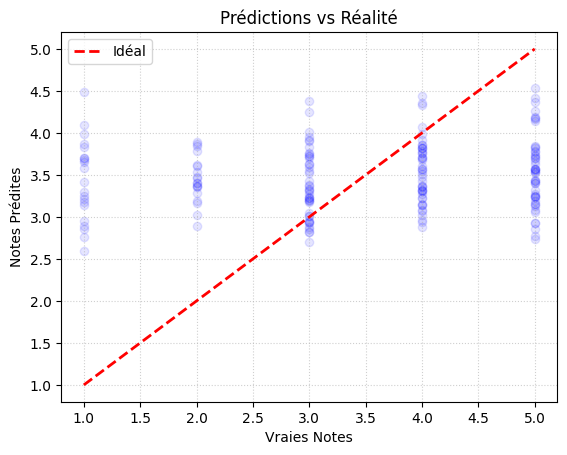

In [132]:
# Isolation de la colonne petSupply 5
pet_supplies_x_train = x_train[x_train['category'] == 'Books_5']
pet_supplies_x_test = x_test[x_test['category'] == 'Books_5']
pet_supplies_y_train = y_train.loc[pet_supplies_x_train.index]
pet_supplies_y_test = y_test.loc[pet_supplies_x_test.index]

# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_')
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [50,100,500,1000,2000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search_linear_regression.fit(pet_supplies_x_train, pet_supplies_y_train)

print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")


prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(pet_supplies_x_test)

displayMetriquesAndGraph(pet_supplies_y_test,prediction_linear_regression)

### 1.3 Régression avec le texte - Ridge

Processeur : drop
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 5000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 2)}
Meilleure RMSE : 1.475
Mse: 1.4618707284318546
RMSE: 1.209078462479526
R2 Score: 0.1858458475060204


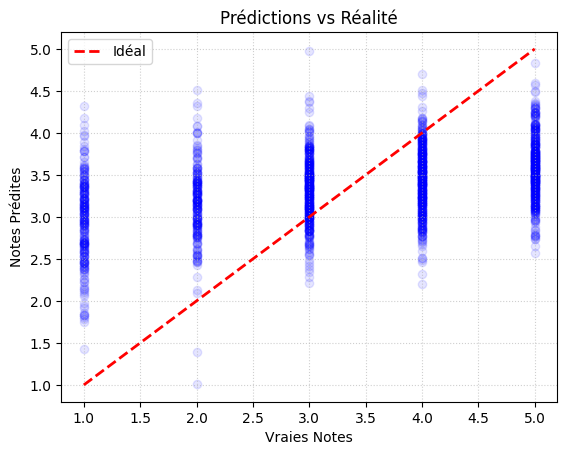

In [116]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction)

### 1.3.1 Analyse des mots les plus utilisés

In [117]:
best_model = reg_search.best_estimator_
vectorizer = best_model.named_steps['preprocessor'].transformers_[0][1]
ridge_clf = best_model.named_steps['classifier']

feature_names = vectorizer.get_feature_names_out()

df_coeffs = pd.DataFrame({
    'mot': feature_names,
    'coefficient': ridge_clf.coef_
})

print("--- Mots les plus associés à une note ÉLEVÉE ---")
print(df_coeffs.sort_values(by='coefficient', ascending=False).head(10))

print("\n--- Mots les plus associés à une note FAIBLE ---")
print(df_coeffs.sort_values(by='coefficient', ascending=True).head(10))

--- Mots les plus associés à une note ÉLEVÉE ---
            mot  coefficient
1339       love     2.150072
966       great     1.761764
737   excellent     1.253364
1617    perfect     1.178417
58      amazing     1.134356
735     exactly     1.084332
669        easy     1.022912
118     awesome     0.960149
2538  wonderful     0.760718
1985     series     0.755785

--- Mots les plus associés à une note FAIBLE ---
               mot  coefficient
1899        return    -2.153556
2480         waste    -1.738107
610   disappointed    -1.513248
1167          junk    -1.333321
2298      terrible    -1.324426
1674          poor    -1.271335
264          break    -1.223692
126            bad    -1.223382
1080      horrible    -1.158504
384          cheap    -1.124822


### 1.4 Lasso

Processeur : drop
Fitting 5 folds for each of 126 candidates, totalling 630 fits
Meilleurs paramètres : {'classifier__alpha': 0.0001, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 1)}
Meilleure RMSE : 1.496
Mse: 1.4728222374773516
RMSE: 1.2135988783273293
R2 Score: 0.17974666486828395


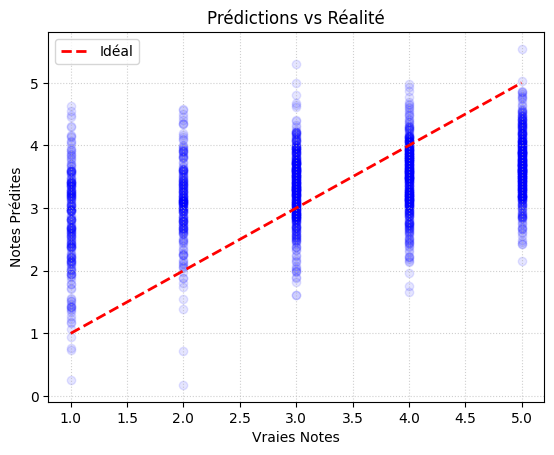

In [118]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Lasso())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha': [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

displayMetriquesAndGraph(y_test,prediction)


## 2. Synthèse des expérimentations et des résultats obtenus

### Brouillon